**1. Import Library**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

**2. Load Dataset**

In [ ]:
data = pd.read_csv("/content/drive/MyDrive/BDDM/UAS/wdbc.data")
data.head()

,842302,M,17.99,10.38,122.8,1001,0.1184,0.2776,0.3001,0.1471,...,25.38,17.33,184.6,2019,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
0,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
1,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
2,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
3,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678
4,843786,M,12.45,15.70,82.57,477.1,0.12780,0.17000,0.1578,0.08089,...,15.47,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440


**3. Data Preprocessing**

In [ ]:
data.rename(columns={'842302': 'id', 'M': 'diagnosis'}, inplace=True)

data = data.drop(columns=['id', 'Unnamed: 32'], errors='ignore')

data['diagnosis'] = data['diagnosis'].map({'M': 1, 'B': 0})

print(data.isnull().sum())

diagnosis    0
17.99        0
10.38        0
122.8        0
1001         0
0.1184       0
0.2776       0
0.3001       0
0.1471       0
0.2419       0
0.07871      0
1.095        0
0.9053       0
8.589        0
153.4        0
0.006399     0
0.04904      0
0.05373      0
0.01587      0
0.03003      0
0.006193     0
25.38        0
17.33        0
184.6        0
2019         0
0.1622       0
0.6656       0
0.7119       0
0.2654       0
0.4601       0
0.1189       0
dtype: int64


**4. Exploratory Data Analysis (EDA)**

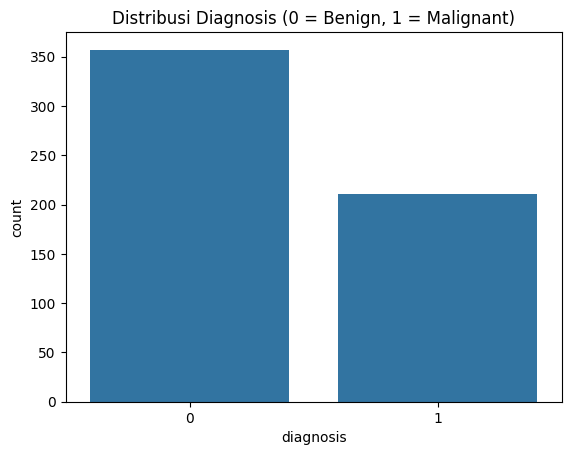

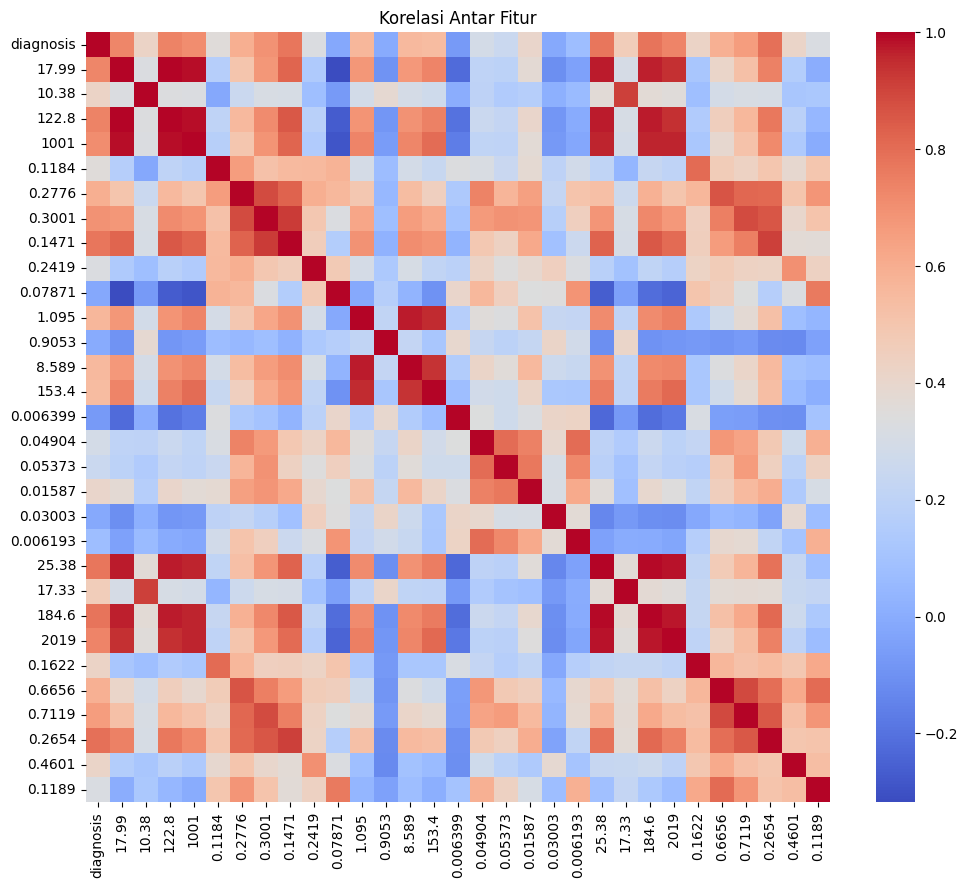

In [ ]:
sns.countplot(x=data['diagnosis'])
plt.title("Distribusi Diagnosis (0 = Benign, 1 = Malignant)")
plt.show()

plt.figure(figsize=(12,10))
sns.heatmap(data.corr(), cmap="coolwarm")
plt.title("Korelasi Antar Fitur")
plt.show()

**5. Feature Selection**

In [ ]:
X = data.drop('diagnosis', axis=1)
y = data['diagnosis']

selector = SelectKBest(score_func=f_classif, k=10)
X_new = selector.fit_transform(X, y)

selected_features = X.columns[selector.get_support()]
print("Fitur terpilih:", selected_features)

Fitur terpilih: Index(['17.99', '122.8', '1001', '0.3001', '0.1471', '25.38', '184.6', '2019',
       '0.7119', '0.2654'],
      dtype='object')


**6. Modeling (SVM, Random Forest, Decision Tree, KNN)**

In [ ]:
# Split data (ensure this is executed only once, ideally before any model training)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Pipeline untuk SVM
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC(kernel='rbf', C=1, gamma='scale'))
])

svm_pipeline.fit(X_train, y_train)
svm_pred = svm_pipeline.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, svm_pred))
print(confusion_matrix(y_test, svm_pred))
print(classification_report(y_test, svm_pred))

# Pipeline untuk Random Forest
rf_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestClassifier(n_estimators=100, random_state=42))
])

rf_pipeline.fit(X_train, y_train)
rf_pred = rf_pipeline.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))
print(confusion_matrix(y_test, rf_pred))
print(classification_report(y_test, rf_pred))


# Pipeline untuk Decision Tree
dt_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', DecisionTreeClassifier(random_state=42))
])

dt_pipeline.fit(X_train, y_train)
dt_pred = dt_pipeline.predict(X_test)

print("\nDecision Tree Accuracy:", accuracy_score(y_test, dt_pred))
print(confusion_matrix(y_test, dt_pred))
print(classification_report(y_test, dt_pred))

# Pipeline untuk KNN
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

knn_pipeline.fit(X_train, y_train)
knn_pred = knn_pipeline.predict(X_test)

print("\nKNN Accuracy:", accuracy_score(y_test, knn_pred))
print(confusion_matrix(y_test, knn_pred))
print(classification_report(y_test, knn_pred))

SVM Accuracy: 0.956140350877193
[[67  1]
 [ 4 42]]
              precision    recall  f1-score   support

           0       0.94      0.99      0.96        68
           1       0.98      0.91      0.94        46

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

Random Forest Accuracy: 0.9736842105263158
[[68  0]
 [ 3 43]]
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        68
           1       1.00      0.93      0.97        46

    accuracy                           0.97       114
   macro avg       0.98      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114


Decision Tree Accuracy: 0.9210526315789473
[[64  4]
 [ 5 41]]
              precision    recall  f1-score   support

           0       0.93      0.94      0.93        68
           1       0.91      0.89      0.90        46

    ac

**8. Confusion Matrix**

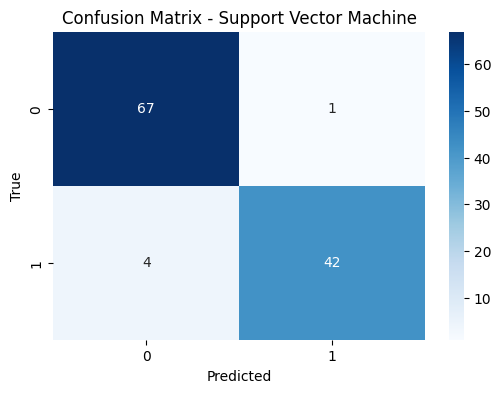

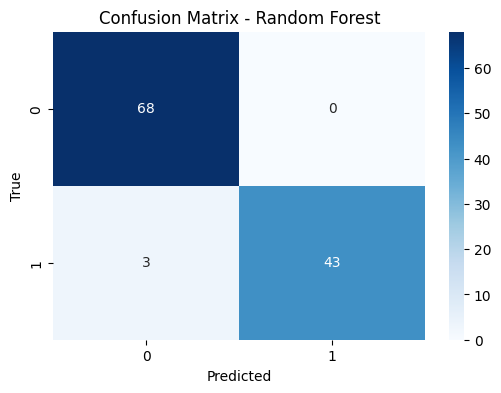

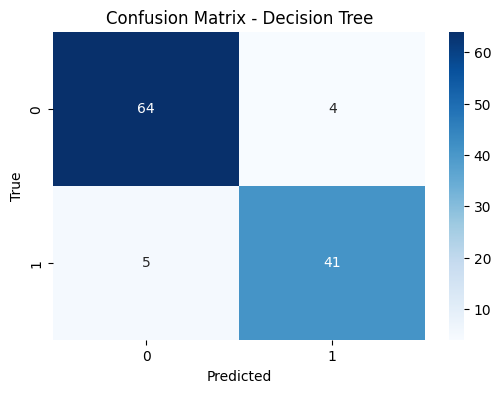

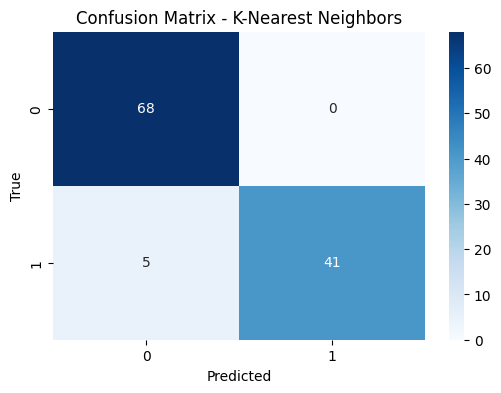

In [ ]:
# Confusion Matrix for SVM
cm_svm = confusion_matrix(y_test, svm_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_svm, annot=True, cmap="Blues", fmt='g')
plt.title("Confusion Matrix - Support Vector Machine")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

# Confusion Matrix for Random Forest
cm_rf = confusion_matrix(y_test, rf_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_rf, annot=True, cmap="Blues", fmt='g')
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

# Confusion Matrix for Decision Tree
cm_dt = confusion_matrix(y_test, dt_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_dt, annot=True, cmap="Blues", fmt='g')
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

# Confusion Matrix for KNN
cm_knn = confusion_matrix(y_test, knn_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_knn, annot=True, cmap="Blues", fmt='g')
plt.title("Confusion Matrix - K-Nearest Neighbors")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()